# Figure 5: Mixed vs. Blocked SNR

Translation of `Figure05_mixedVsBlockedSNR.m`

## What this notebook does

Compares how participants' decision bounds relate to SNR in two task variants:

- **OL (Blocked SNR)**: Each block contains only one SNR level; subjects know which SNR applies.
- **MX (Mixed SNR)**: Multiple SNR levels are interleaved within a block; subjects must infer the SNR.

The hypothesis: in mixed SNR, subjects cannot set SNR-specific bounds, so low-SNR and high-SNR
bounds should be more similar than in blocked SNR.

**Figure** — 2 rows (OL / MX) × 3 columns (blocks 1–3):
Reward-rate heatmap (coins per trial vs. lo × hi SNR bound pair), with per-subject mean bounds
overlaid as open circles. The near-optimal region (≥ 95 % of max RR) is outlined with a thin
blue contour, and the single optimal grid point is marked with a large filled blue circle; a
large filled red circle marks the median of the participant data. All three are drawn above the
per-subject scatter so they stay visible where points overlap them. Wilcoxon signed-rank test
(lo vs. hi bound per subject) reported in the panel title.

**Data**: Blocks 1–3, pre-filtered to `DT > 2` (keeps DT ≥ 3), all subjects.

## Imports

Standard scientific Python libraries plus `get_data_table`, `get_bound_summary`, and
`get_simulated_data_table`. No data loading or analysis here.

## Load data

Loads both task variants:
- `data_table_mx`: Mixed-SNR (MX) task — multiple SNR levels interleaved within each block.
- `data_table_ol`: Online / Blocked-SNR (OL) task — one SNR level per block.

Both calls apply internal processing: bound/DT computation, wall-hit marking, bias correction,
and block merging (6 → 3 blocks). No trials are dropped at this stage.

## Parameters and RR-matrix computation

**`MIN_DT`**: Pre-filter applied before `get_bound_summary`; keeps DT ≥ 3 (matching MATLAB `minDT=2`).

**`BLOCKS`**: All three blocks analysed: block 1 (gain only), block 2 (coin penalty for errors),
block 3 (step loss for errors).

**`RR_BOUNDS`**: Bound grid for the reward-rate simulation (0.01 to 0.76 in steps of 0.05, 16
values — matching MATLAB `rrBounds = 0.01:0.05:0.76`).

**`NUM_RR_REPS`**: Number of simulated subjects per condition (matching MATLAB `numRRReps=100`).

**`G_MEANS`**: Generative means for lo and hi SNR (matching MATLAB defaults `[0.05 0.15]`).

**`COMPUTE_RR`**: Set to `False` to skip the slow simulation and show only the scatter overlay.
The simulation takes ~1 min per block for OL and ~15 min per block for MX.

**`rr_matrices`**: Dict keyed by `(task_type, block)`. Both OL and MX are stored as
`rr_matrix[hi_idx, lo_idx]` so `imshow(origin='lower')` places lo-SNR bound on the x-axis and
hi-SNR bound on the y-axis, matching the scatter overlay and axis labels.

**`get_bound_summary` internal filters** (via `get_good_trial_array`):
`DT ≥ 2`, `trial_number ≥ 10`, `bound` finite and non-zero, `correct ≥ 0`, `wall_hit = False`.

**Data included**: All subjects, each block separately, all SNR levels (sorted ascending:
index 0 = lo SNR, index −1 = hi SNR).

**Data excluded**: Subjects with fewer than 2 valid SNR levels (panel skipped).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.stats import get_bound_summary
from pigeon.simulate import get_simulated_data_table
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label

In [2]:
data_table_mx = get_data_table(task_type='MX')
data_table_ol = get_data_table(task_type='OL')

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.32.506.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h28.25.851.csv
 22: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.22.933.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.24.102.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.07.354.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.12.482.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.49.710.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_19h25.58.493.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_12h13.32.209.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-12-06_15h08.34.504.csv


  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h34.58.360.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h07.36.399.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h09.54.461.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h41.01.524.csv


In [3]:
# ── Parameters ────────────────────────────────────────────────────────────────
MIN_DT      = 2                             # keep DT > MIN_DT (i.e. DT ≥ 3)
BLOCKS      = [1, 2, 3]                     # all three task blocks
RR_BOUNDS   = np.arange(0.01, 0.81, 0.05)  # bound grid: 0.01:0.05:0.76 (16 values)
NUM_RR_REPS = 100                           # simulated subjects per RR computation
G_MEANS     = [0.05, 0.15]                 # lo and hi SNR generative means
COMPUTE_RR  = True                          # False = skip slow simulation

BLOCK_LABELS = {1: 'block 1', 2: 'block 2', 3: 'block 3'}

rng = np.random.default_rng(42)


# ── Helper: simulate reward-rate matrix ───────────────────────────────────────
def compute_rr_matrix(task_type, block, rr_bounds, num_reps, g_means, rng):
    """Compute expected reward rate over a lo-SNR-bound × hi-SNR-bound grid.

    Both OL and MX return rr_matrix[hi_idx, lo_idx] so that imshow(origin='lower')
    displays the matrix with lo-SNR bound on the x-axis and hi-SNR bound on the
    y-axis, matching the scatter overlay and axis labels.

    For OL (blocked SNR): lo and hi SNR blocks are simulated separately for each
    bound value. Their mean coin counts are added, matching MATLAB's accumulation:
        RRMatrix_(:, b1) += mean(loCoinCounts)   [column b1 = lo-bound]
        RRMatrix_(b1, :) += mean(hiCoinCounts)   [row b1 = hi-bound]
    → rr_matrix[hi_idx, lo_idx]

    For MX (mixed SNR): each (lo_bound, hi_bound) pair requires its own
    simulation with both SNR levels interleaved (equivalent to MATLAB's
    boundType='varBySNR'). Stored as rr_matrix[hi_idx, lo_idx] to match OL.
    """
    n = len(rr_bounds)
    rr_matrix = np.zeros((n, n))
    specs = {'num_subjects': num_reps, 'blocks': [block]}

    if task_type == 'OL':
        for b1, bnd in enumerate(rr_bounds):
            print(f'  OL block {block} RR matrix: bound {b1 + 1}/{n}', end='\r')

            lo_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[0],
                bound_mean=bnd, correct_bias=None, rng=rng)
            lo_coins = lo_table.groupby('subject_index')['coin_count'].last().mean()

            hi_table = get_simulated_data_table(
                specs=specs, generative_mean=g_means[1],
                bound_mean=bnd, correct_bias=None, rng=rng)
            hi_coins = hi_table.groupby('subject_index')['coin_count'].last().mean()

            rr_matrix[:, b1] += lo_coins
            rr_matrix[b1, :] += hi_coins

    else:  # MX — stored as rr_matrix[hi_idx, lo_idx] to match OL display convention
        for b1, lo_bnd in enumerate(rr_bounds):
            print(f'  MX block {block} RR matrix: lo-bound {b1 + 1}/{n}', end='\r')
            for b2, hi_bnd in enumerate(rr_bounds):
                mx_table = get_simulated_data_table(
                    specs=specs,
                    generative_mean=list(g_means),
                    bound_mean=[lo_bnd, hi_bnd],
                    correct_bias=None, rng=rng)
                rr_matrix[b2, b1] = (
                    mx_table.groupby('subject_index')['coin_count'].last().mean())
    print()
    return rr_matrix


# ── Helper: heatmap + scatter panel ───────────────────────────────────────────
def _plot_heatmap_panel(ax, data_table, block, min_dt, rr_bounds, rr_matrix, vmax=None):
    """Lo × hi SNR bound heatmap with subject scatter.

    Returns `(wilcoxon_p, image)`, where `image` is the `AxesImage` from `imshow`
    (or `None` if no RR matrix was available) so callers can build a shared
    colorbar from it. If `vmax` is given, it sets the color scale (use a value
    shared across panels for a comparable colorbar); otherwise each panel is
    normalized to its own max.
    """
    this_table = data_table[data_table['DT'] > min_dt].reset_index(drop=True)
    bs_all = get_bound_summary(this_table, blocks=[block], max_rt='all')

    if bs_all.shape[2] < 2:
        ax.axis('off')
        return None, None

    lo = bs_all[:, 0,  0, 0, 0]   # mean abs bound, lo SNR, all DTs collapsed
    hi = bs_all[:, 0, -1, 0, 0]   # mean abs bound, hi SNR, all DTs collapsed

    b_min, b_max = rr_bounds[0], rr_bounds[-1]

    im = None
    if rr_matrix is not None:
        panel_vmax = rr_matrix.max() if vmax is None else vmax
        im = ax.imshow(
            rr_matrix, origin='lower',
            extent=[b_min - 0.025, b_max + 0.025, b_min - 0.025, b_max + 0.025],
            aspect='auto', vmin=0, vmax=panel_vmax, cmap='viridis', zorder=0)

    ax.plot([0, 0.75], [0, 0.75], 'k:', linewidth=1, zorder=1)

    valid = np.isfinite(lo) & np.isfinite(hi)
    ax.plot(lo[valid], hi[valid], 'ko', markerfacecolor='white',
            markersize=8, markeredgewidth=1.5, zorder=2)

    if rr_matrix is not None:
        # RR-landscape summary is drawn last (above the participant scatter) so
        # it isn't obscured by the data points. The near-optimal (>=95% of max
        # RR) region is outlined with a thin blue contour; the single peak grid
        # point gets a large filled blue circle. A large filled red circle marks
        # the median of the participant data, for a direct visual comparison
        # between where subjects actually sit and where the RR landscape peaks.
        # (This thresholding always uses the panel's own max, independent of
        # the shared colorbar scale passed via `vmax`.)
        near_opt = rr_matrix >= 0.95 * rr_matrix.max()
        lo_grid, hi_grid = np.meshgrid(rr_bounds, rr_bounds)
        ax.contour(lo_grid, hi_grid, near_opt.astype(float), levels=[0.5],
                   colors='tab:blue', linewidths=1, zorder=3)

        opt_hi, opt_lo = np.unravel_index(rr_matrix.argmax(), rr_matrix.shape)
        ax.plot(rr_bounds[opt_lo], rr_bounds[opt_hi], 'o', color='tab:blue',
                markersize=11, markeredgecolor='k', markeredgewidth=1, zorder=4)

    if valid.sum():
        ax.plot(np.nanmedian(lo[valid]), np.nanmedian(hi[valid]), 'o', color='red',
                markersize=11, markeredgecolor='k', markeredgewidth=1, zorder=5)

    ax.set_xlim(0, 0.75)
    ax.set_ylim(0, 0.75)
    ax.set_aspect('equal')

    if valid.sum() > 2:
        _, p = scipy.stats.wilcoxon(lo[valid], hi[valid])
        return p, im
    return None, im


# ── Task list ─────────────────────────────────────────────────────────────────
tasks = [
    (data_table_ol, 'OL (Blocked SNR)', 'OL'),
    (data_table_mx, 'MX (Mixed SNR)',   'MX'),
]

# ── Compute RR matrices: keyed by (task_type, block) ─────────────────────────
rr_matrices = {}

if COMPUTE_RR:
    for _, label, task_type in tasks:
        for block in BLOCKS:
            print(f'Computing RR matrix for {task_type} block {block}...')
            rr_matrices[(task_type, block)] = compute_rr_matrix(
                task_type, block, RR_BOUNDS, NUM_RR_REPS, G_MEANS, rng)
            print(f'  Done.')

Computing RR matrix for OL block 1...



  Done.
Computing RR matrix for OL block 2...



  Done.
Computing RR matrix for OL block 3...



  Done.
Computing RR matrix for MX block 1...



  Done.
Computing RR matrix for MX block 2...



  Done.
Computing RR matrix for MX block 3...



  Done.


## Figure

Publication-quality figure at 14 cm wide (≈ 2.4 JNeurosci columns): 2 rows (OL / MX) × 3 columns
(blocks 1–3) of heatmap + scatter panels, each row with its own colorbar to the right. Panel
width = height = 4 cm; gaps 1.0 cm (horizontal) × 1.3 cm (vertical). Block label in column header
(top row); Wilcoxon p in each panel title; task-type row label on the left y-axis. Each row's 3
panels share one reward-rate color scale (normalized to the max across that row's RR matrices);
OL and MX use separate scales since their reward rates aren't on the same footing. Saves to
`Figure05.pdf`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


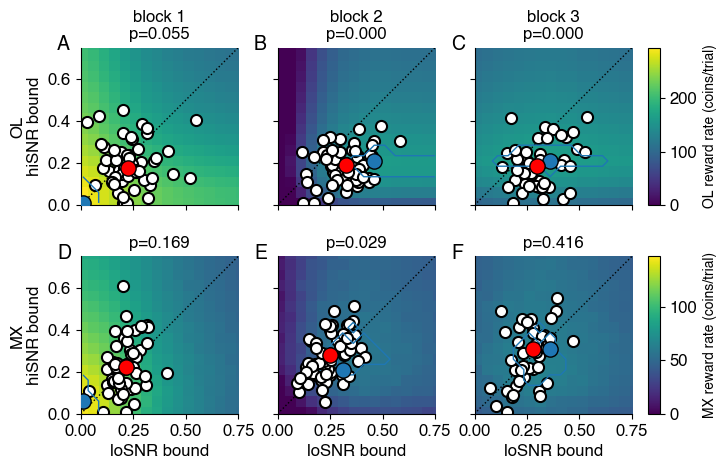

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05.pdf


In [4]:
# ── Main figure: 2 rows (OL/MX) × 3 cols (blocks 1–3), heatmap panels ────────
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 14.0           # panel-grid width (cm)
HTS = [4.0, 4.0]     # row heights (cm) — matches panel width for square axes
PSH = 1.3            # vertical panel separation (cm)
PSW = 1.0            # horizontal panel separation (cm)
FS  = 12             # font size (pt)
CBAR_W   = 0.3       # colorbar width (cm)
CBAR_PAD = 0.4       # gap between panel grid and colorbar (cm)

n_rows  = len(tasks)
n_cols  = len(BLOCKS)
fig_h   = sum(HTS) + PSH * (n_rows - 1)
panel_w = (WID - PSW * (n_cols - 1)) / n_cols  # = 4.0 cm → square panels

hspace = PSH / np.mean(HTS)
wspace = PSW / panel_w

fig_w = WID + CBAR_PAD + CBAR_W   # total figure width, including colorbar strip

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

fig_main = plt.figure(figsize=(fig_w * CM, fig_h * CM))
panel_right = WID / fig_w   # fraction of total figure width used by the panel grid
gs = gridspec.GridSpec(n_rows, n_cols, figure=fig_main,
                       left=0, right=panel_right, bottom=0, top=1,
                       hspace=hspace, wspace=wspace)
axs = np.array([[fig_main.add_subplot(gs[r, c])
                 for c in range(n_cols)] for r in range(n_rows)])

# Each row (task type) gets its own color scale, shared across that row's 3
# blocks — OL and MX reward rates aren't on the same footing, so a single
# figure-wide scale would wash out one row's structure relative to the other.
row_vmax = {
    row_idx: max((rr_matrices[(task_type, block)].max()
                   for block in BLOCKS if (task_type, block) in rr_matrices),
                  default=None)
    for row_idx, (_, _, task_type) in enumerate(tasks)
}

row_im = {}
for row_idx, (data_table, task_label, task_type) in enumerate(tasks):
    for col_idx, block in enumerate(BLOCKS):
        ax = axs[row_idx, col_idx]
        p, panel_im = _plot_heatmap_panel(
            ax, data_table, block, MIN_DT, RR_BOUNDS,
            rr_matrices.get((task_type, block)), vmax=row_vmax[row_idx])
        if panel_im is not None:
            row_im[row_idx] = panel_im

        # Column label (top row only) + Wilcoxon p
        p_str = f'p={p:.3f}' if p is not None else ''
        title = (BLOCK_LABELS[block] + '\n' if row_idx == 0 else '') + p_str
        ax.set_title(title)

        # y-axis: row label + unit on leftmost column
        if col_idx == 0:
            ax.set_ylabel(f'{task_type}\nhiSNR bound')
        else:
            ax.tick_params(axis='y', labelleft=False)

        # x-axis on bottom row only
        if row_idx == n_rows - 1:
            ax.set_xlabel('loSNR bound')
        else:
            ax.tick_params(axis='x', labelbottom=False)

        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        add_panel_label(ax, chr(65 + row_idx * n_cols + col_idx))

# One colorbar per row, vertically aligned with that row's panels, each on its
# own (row-shared) reward-rate scale.
for row_idx, (_, _, task_type) in enumerate(tasks):
    if row_idx not in row_im:
        continue
    y0, y1 = axs[row_idx, 0].get_position().y0, axs[row_idx, 0].get_position().y1
    cax = fig_main.add_axes([(WID + CBAR_PAD) / fig_w, y0, CBAR_W / fig_w, y1 - y0])
    cbar = fig_main.colorbar(row_im[row_idx], cax=cax)
    cbar.set_label(f'{task_type} reward rate (coins/trial)', fontsize=FS - 2)

out = FIGURES_DIR / 'Figure05.pdf'
fig_main.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')

## Hi/Lo SNR bound ratio summary

For each condition and block, prints two statistics about the ratio of the high-SNR to low-SNR bound:

1. **Per-participant median [IQR]**: the ratio `hi_bound / lo_bound` computed per subject (using
   the same all-DT-collapsed mean bounds as the heatmap scatter), summarised as
   median [25th–75th percentile] across subjects.
2. **Ratio at the optimal reward rate**: `rr_bounds[opt_hi_idx] / rr_bounds[opt_lo_idx]`, where
   the optimal index is the argmax of the simulated RR matrix.  Requires `COMPUTE_RR = True`.

Both OL and MX matrices are stored as `rr_matrix[hi_idx, lo_idx]`, so `argmax` → `(hi_idx, lo_idx)`
for both.

In [5]:
# ── Hi/Lo SNR bound ratio: per-participant and at optimal RR ──────────────────
print('Ratio of Hi-SNR to Lo-SNR bound\n')

for data_table, label, task_type in tasks:
    print(f'{label}:')
    for block in BLOCKS:
        this_table = data_table[data_table['DT'] > MIN_DT].reset_index(drop=True)
        bs_all = get_bound_summary(this_table, blocks=[block], max_rt='all')

        if bs_all.shape[2] < 2:
            print(f'  Block {block}: insufficient SNR levels')
            continue

        lo = bs_all[:, 0,  0, 0, 0]
        hi = bs_all[:, 0, -1, 0, 0]

        valid = np.isfinite(lo) & np.isfinite(hi) & (lo > 0)
        ratio = hi[valid] / lo[valid]

        med      = np.median(ratio)
        q25, q75 = np.percentile(ratio, [25, 75])

        rr_key = (task_type, block)
        if rr_key in rr_matrices:
            rm = rr_matrices[rr_key]
            opt_hi_idx, opt_lo_idx = np.unravel_index(rm.argmax(), rm.shape)
            opt_lo = RR_BOUNDS[opt_lo_idx]
            opt_hi = RR_BOUNDS[opt_hi_idx]
            rr_str = f'{opt_hi / opt_lo:.3f}  (lo={opt_lo:.2f}, hi={opt_hi:.2f})'
        else:
            rr_str = 'not available (COMPUTE_RR=False)'

        print(f'  Block {block}:  median [IQR] = {med:.3f} [{q25:.3f}, {q75:.3f}];'
              f'  optimal RR ratio = {rr_str}')
    print()

Ratio of Hi-SNR to Lo-SNR bound

OL (Blocked SNR):
  Block 1:  median [IQR] = 0.781 [0.586, 1.286];  optimal RR ratio = 1.000  (lo=0.01, hi=0.01)
  Block 2:  median [IQR] = 0.544 [0.398, 0.779];  optimal RR ratio = 0.457  (lo=0.46, hi=0.21)
  Block 3:  median [IQR] = 0.639 [0.400, 0.826];  optimal RR ratio = 0.583  (lo=0.36, hi=0.21)

MX (Mixed SNR):
  Block 1:  median [IQR] = 1.079 [0.750, 1.445];  optimal RR ratio = 6.000  (lo=0.01, hi=0.06)
  Block 2:  median [IQR] = 1.127 [0.879, 1.442];  optimal RR ratio = 0.677  (lo=0.31, hi=0.21)
  Block 3:  median [IQR] = 1.048 [0.742, 1.345];  optimal RR ratio = 0.861  (lo=0.36, hi=0.31)

